# Introduction to Parametric Quantum Circuits

Parametric quantum circuits are a building block of **variational quantum algorithms (VQAs)**, including the **Quantum Approximate Optimization Algorithm (QAOA)**. Their gate angles are represented by symbolic parameters. A classical optimizer adjusts these angles to improve an objective while keeping the circuit structure fixed.

This notebook introduces parameter handling in Qiskit through a simple two-qubit example. We will:

- Create a circuit with symbolic rotation angles.
- See why numerical parameter values are required for execution.
- Assign values without modifying the original circuit.
- Run the resulting circuit on an ideal local simulator and inspect its measurement outcomes.

This example focuses on parameter binding; the classical optimization loop will be introduced in later notebooks.

In [1]:
import numpy as np
import copy

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import SamplerV2 as Sampler
ideal_simulator = AerSimulator()
sampler = Sampler(mode=ideal_simulator)

# Needed for parametric circuits 
from qiskit.circuit import Parameter


## Parametric Circuits

A parametric circuit contains gates with symbolic parameters instead of fixed numerical values. For example, the rotation angle of an \(R_x\), \(R_y\), or \(R_z\) gate can be represented by a parameter and assigned a numerical value before execution.

### Creating a Parametric Circuit

We use Qiskit's `Parameter` class to define two symbolic rotation angles. The circuit below combines rotations with fixed angles and rotations with symbolic angles, then measures both qubits.

In [2]:
# needed for parametric circuits 
from qiskit.circuit import Parameter


In [3]:
qc=QuantumCircuit(2)

# defining variable to be used as the input argument of the single-qubit gate
var1_name=f'gamma_1'
var1 = Parameter(var1_name)

var2_name=r'$\beta_2$'
var2= Parameter(var2_name)

qc.rz(np.pi/2, 0)
qc.rz(var1, 1)

qc.rx(var2, 0)
qc.ry(np.pi/4, 1)

qc.measure_all()
print(qc)

          ┌─────────┐  ┌───────────────┐ ░ ┌─┐   
   q_0: ──┤ Rz(π/2) ├──┤ Rx($\beta_2$) ├─░─┤M├───
        ┌─┴─────────┴─┐└──┬─────────┬──┘ ░ └╥┘┌─┐
   q_1: ┤ Rz(gamma_1) ├───┤ Ry(π/4) ├────░──╫─┤M├
        └─────────────┘   └─────────┘    ░  ║ └╥┘
meas: 2/════════════════════════════════════╩══╩═
                                            0  1 


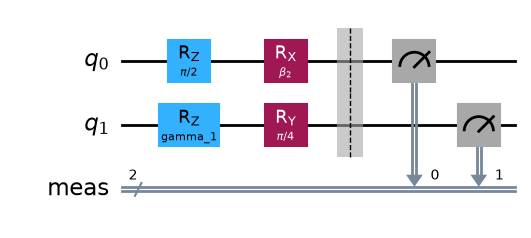

In [4]:
qc.draw('mpl')

### Running the Circuit on a Local Simulator

Before running the circuit, predict its measurement outcomes:

- Which bitstrings do you expect to observe?
- What probability would you assign to each bitstring?

Then run the cell below to check your prediction.

In [5]:
shots=10**4

# Perform an ideal simulation
job = sampler.run([qc], shots=shots)
result_ideal = job.result()

#displaying results 
print(f'Running the parametric circuit?')
print('Outcomes')
for x, f in count_ideal.items():
    print(f'    {x}: {(f*100)/shots:.2f}% \t ({f}/{shots})')

ValueError: The number of values (0) does not match the number of parameters (2) for the circuit. Note that if you want to run a single pub, you need to wrap it with `[]` like `sampler.run([(circuit, param_values)])` instead of `sampler.run((circuit, param_values))`.

### Why Did Execution Fail?

The circuit contains two symbolic parameters whose numerical values have not been assigned. The simulator therefore cannot determine the rotation angles needed to execute the gates.

Before running the circuit, we must supply a numerical value for each parameter. Next, we will use `assign_parameters` to set these values.

## Assigning Parameter Values

We use `assign_parameters` to replace each symbolic parameter with a numerical rotation angle. This creates an executable circuit while leaving the original parametric circuit unchanged.

In [7]:
# Before executing, we must set the value of all parameters
new_circuit=copy.deepcopy(qc)

# all parameters and their values are collected here
mapping={}
mapping[var1_name]=np.pi/3
mapping[var2_name]=np.pi/7

# now, we are ready to fix all parameters 
new_circuit=new_circuit.assign_parameters(mapping)

print(new_circuit)
print()

        ┌─────────┐┌─────────┐ ░ ┌─┐   
   q_0: ┤ Rz(π/2) ├┤ Rx(π/7) ├─░─┤M├───
        ├─────────┤├─────────┤ ░ └╥┘┌─┐
   q_1: ┤ Rz(π/3) ├┤ Ry(π/4) ├─░──╫─┤M├
        └─────────┘└─────────┘ ░  ║ └╥┘
meas: 2/══════════════════════════╩══╩═
                                  0  1 



### The Circuit is Ready to Execute 


With these numerical values, revisit your prediction:

- Which bitstrings do you expect to observe?
- What probability would you assign to each bitstring?

In [8]:
shots=10**4

# Perform an ideal simulation
job = sampler.run([new_circuit], shots=shots)
result_ideal = job.result()
count_ideal=result_ideal[0].data.meas.get_counts()

#displaying results 
print(f'Running the parametric circuit?')
print('Outcomes')
for x, f in count_ideal.items():
    print(f'    {x}: {(f*100)/shots:.2f}% \t ({f}/{shots})')

print('This was a random circuit...')

Running the parametric circuit?
Outcomes
    00: 81.89% 	 (8189/10000)
    10: 13.57% 	 (1357/10000)
    01: 3.92% 	 (392/10000)
    11: 0.62% 	 (62/10000)
This was a random circuit...


### Notes on Parameter Binding and Compilation

- **Parameter binding preserves the circuit structure.** Assigning values changes the rotation angles, while the gates, their order, and the qubits they act on remain the same.

- **Parametric circuits can be compiled before assigning values.** Transpilation adapts the circuit to a target device’s supported gates and connectivity. Unlike parameter binding, transpilation may change the circuit structure.

- **Execution requires numerical parameter values.** A parametric circuit cannot run with unspecified angles. Values can be assigned beforehand using `assign_parameters` or supplied alongside the circuit when submitting it to a sampler.

- **This separation is useful in VQAs and QAOA.** We can construct a parametric circuit once and reuse it with different parameter values as the classical optimizer searches for a better solution.